# Generic Scatterplot Explorer

Upload **any CSV dataset**, inspect the available columns, and choose which variables to plot.

The notebook supports:
- **2D scatterplot:** one X variable and one Y variable
- **3D scatterplot:** two X variables and one Y variable
- **2D scatterplot with color:** X and Y on the axes, third numeric variable represented by color

This is useful for exploring possible relationships and discussing suitable hypothesis spaces.

## 1. Upload your dataset

In [1]:
from google.colab import files
import pandas as pd

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

# Remove a common automatically created index column if present
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

print(f'Dataset: {filename}')
print(f'Rows: {df.shape[0]} | Columns: {df.shape[1]}')
display(df.head())

Saving Advertising.csv to Advertising.csv
Dataset: Advertising.csv
Rows: 200 | Columns: 4


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 2. Inspect the available variables

In [2]:
print('All columns:')
for col in df.columns:
    print('-', col)

numeric_columns = df.select_dtypes(include='number').columns.tolist()

print('\nNumeric columns that can be used directly in scatterplots:')
for col in numeric_columns:
    print('-', col)

All columns:
- TV
- radio
- newspaper
- sales

Numeric columns that can be used directly in scatterplots:
- TV
- radio
- newspaper
- sales


## 3. Choose variables

Replace the example column names below with variables from your own dataset.

In [7]:
# Example only — change these names to columns from your dataset
X_VARIABLE = 'TV'
Y_VARIABLE = 'sales'

# Optional third variable for 3D / color plots
Z_VARIABLE = numeric_columns[2] if len(numeric_columns) > 2 else None

print('Selected variables:')
print('X =', X_VARIABLE)
print('Y =', Y_VARIABLE)
print('Z =', Z_VARIABLE)

Selected variables:
X = TV
Y = sales
Z = newspaper


## 4. 2D scatterplot

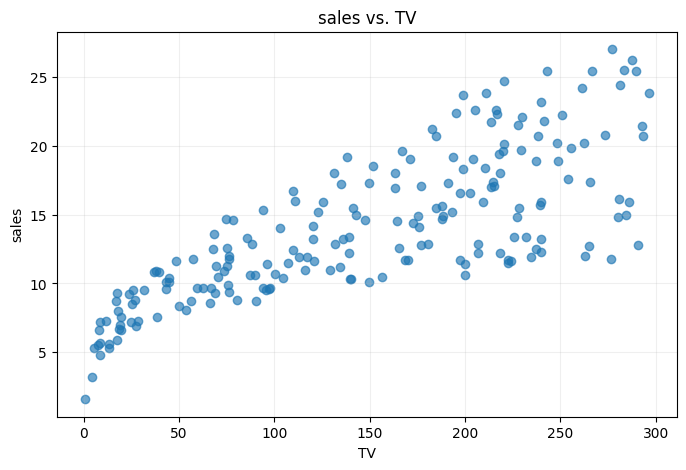

In [8]:
import matplotlib.pyplot as plt

plot_df = df[[X_VARIABLE, Y_VARIABLE]].dropna()

plt.figure(figsize=(8, 5))
plt.scatter(plot_df[X_VARIABLE], plot_df[Y_VARIABLE], alpha=0.65)
plt.xlabel(X_VARIABLE)
plt.ylabel(Y_VARIABLE)
plt.title(f'{Y_VARIABLE} vs. {X_VARIABLE}')
plt.grid(alpha=0.2)
plt.show()

## 5. 3D scatterplot with two input variables

If you want to examine two possible predictors and one target, choose three numeric variables.

- X-axis: first variable
- Y-axis: second variable
- Z-axis: target / outcome variable

In [ ]:
if Z_VARIABLE is None:
    print('The dataset needs at least three numeric columns for a 3D plot.')
else:
    plot3d = df[[X_VARIABLE, Z_VARIABLE, Y_VARIABLE]].dropna()

    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(
        plot3d[X_VARIABLE],
        plot3d[Z_VARIABLE],
        plot3d[Y_VARIABLE],
        alpha=0.65
    )

    ax.set_xlabel(X_VARIABLE)
    ax.set_ylabel(Z_VARIABLE)
    ax.set_zlabel(Y_VARIABLE)
    ax.set_title(f'{Y_VARIABLE} vs. {X_VARIABLE} and {Z_VARIABLE}')
    plt.show()

## 6. Alternative: 2D scatterplot with a third variable shown by color

This often works better for presentation slides than a 3D plot.

In [ ]:
if Z_VARIABLE is None:
    print('The dataset needs at least three numeric columns for this plot.')
else:
    color_df = df[[X_VARIABLE, Y_VARIABLE, Z_VARIABLE]].dropna()

    plt.figure(figsize=(8, 5))
    scatter = plt.scatter(
        color_df[X_VARIABLE],
        color_df[Y_VARIABLE],
        c=color_df[Z_VARIABLE],
        alpha=0.7
    )
    plt.xlabel(X_VARIABLE)
    plt.ylabel(Y_VARIABLE)
    plt.title(f'{Y_VARIABLE} vs. {X_VARIABLE} — color = {Z_VARIABLE}')
    plt.colorbar(scatter, label=Z_VARIABLE)
    plt.grid(alpha=0.2)
    plt.show()

## Discussion questions

1. Which variable could be the **target variable Y**?
2. Which variables could be useful **features X**?
3. What kind of relationship do you observe?
4. Which hypothesis space might be appropriate — for example linear, polynomial, or another model class?
5. Would a more complex hypothesis space likely improve generalization, or could it increase the risk of overfitting?